Наивный байесовский классификатор для фильтрации SMS-спама   
**Цель ноутбука** — реализация мультиномиальной и бернуллиевской моделей наивного Байеса, исследование влияния предобработки и сглаживания Лапласа на качество классификации.   
**Датасет:** [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (UCI Machine Learning Repository) — 5 574 англоязычных SMS-сообщения, из них 747 спам (13,4%). Корпус собран из четырёх источников: 425 спам-сообщений с форума Grumbletext, 3 375 легитимных сообщений из NUS SMS Corpus (Сингапур), 450 легитимных сообщений из диссертации Caroline Tag и SMS Spam Corpus v.0.1 Big (1 002 ham + 322 spam).    
**Классы:** `ham` — легитимное сообщение, `spam` — нежелательное.   
**План работы:**
1) Загрузка и исследование данных.
2) Предобработка текстов.
3) Разделение на обучающую и тестовую выборки.
4) Мультиномиальная модель — обучение и оценка.
5) Модель Бернулли — обучение и оценка.
6) Сравнение моделей.
7) Подбор параметра сглаживания $\alpha$.
8) Анализ информативных признаков.
9) Пример классификации новых сообщений


**Примечание.** Для воспроизводимости достаточно библиотек `numpy`, `pandas`, `matplotlib`, `scikit-learn`. Стемминг и стоп-слова — из библиотеки `nltk`

In [138]:
# Регулярные выражения
import re

# Работа с zip-архивами
import zipfile

# Предобработка текста
import nltk

# Работа с табличными данными
import pandas as pd

# Для математических операций и визуального представления
import numpy as np
import matplotlib.pyplot as plt

# Векторизация текста (реализация Bag-of-Words)
from sklearn.feature_extraction.text import CountVectorizer

# Разделение выборки (train и test) и кросс-валидация
from sklearn.model_selection import train_test_split, cross_val_score

# Мультиномиальная модель и модель Бернулли
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.pipeline import Pipeline

# Метрики
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, confusion_matrix, classification_report,
                            precision_recall_curve)

# Для воспроизводимости результата
RANDOM_STATE = 42

**Загрузка и исследование данных** 
Файл датасета — один текстовый файл `SMSSpamCollection`, где каждая строка имеет вид `метка<TAB>текст`.    
Загрузим скачанные данные из zip-архива.

In [139]:
# Открываем zip-архив
with zipfile.ZipFile("sms+spam+collection.zip") as zfile:

    # Заранее зная позицию файла, инициализируем ссылку на него
    sms_file = zfile.namelist()[0]

    # Октрываем файл и делаем из него pandas-таблицу
    with zfile.open(sms_file) as f:
        df = pd.read_csv(f, sep='\t', header=None, names=["Class", "Text"])
df

,Class,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [140]:
counts = df["Class"].value_counts()
counts

Class
ham     4825
spam     747
Name: count, dtype: int64


Датасет **несбалансирован**: спама в **6.46** меньше легитимных сообщений.   
Это ситуация часто встречается для задачи фильтрации спама.     
Посмотрим на распределение классов и длину сообщений


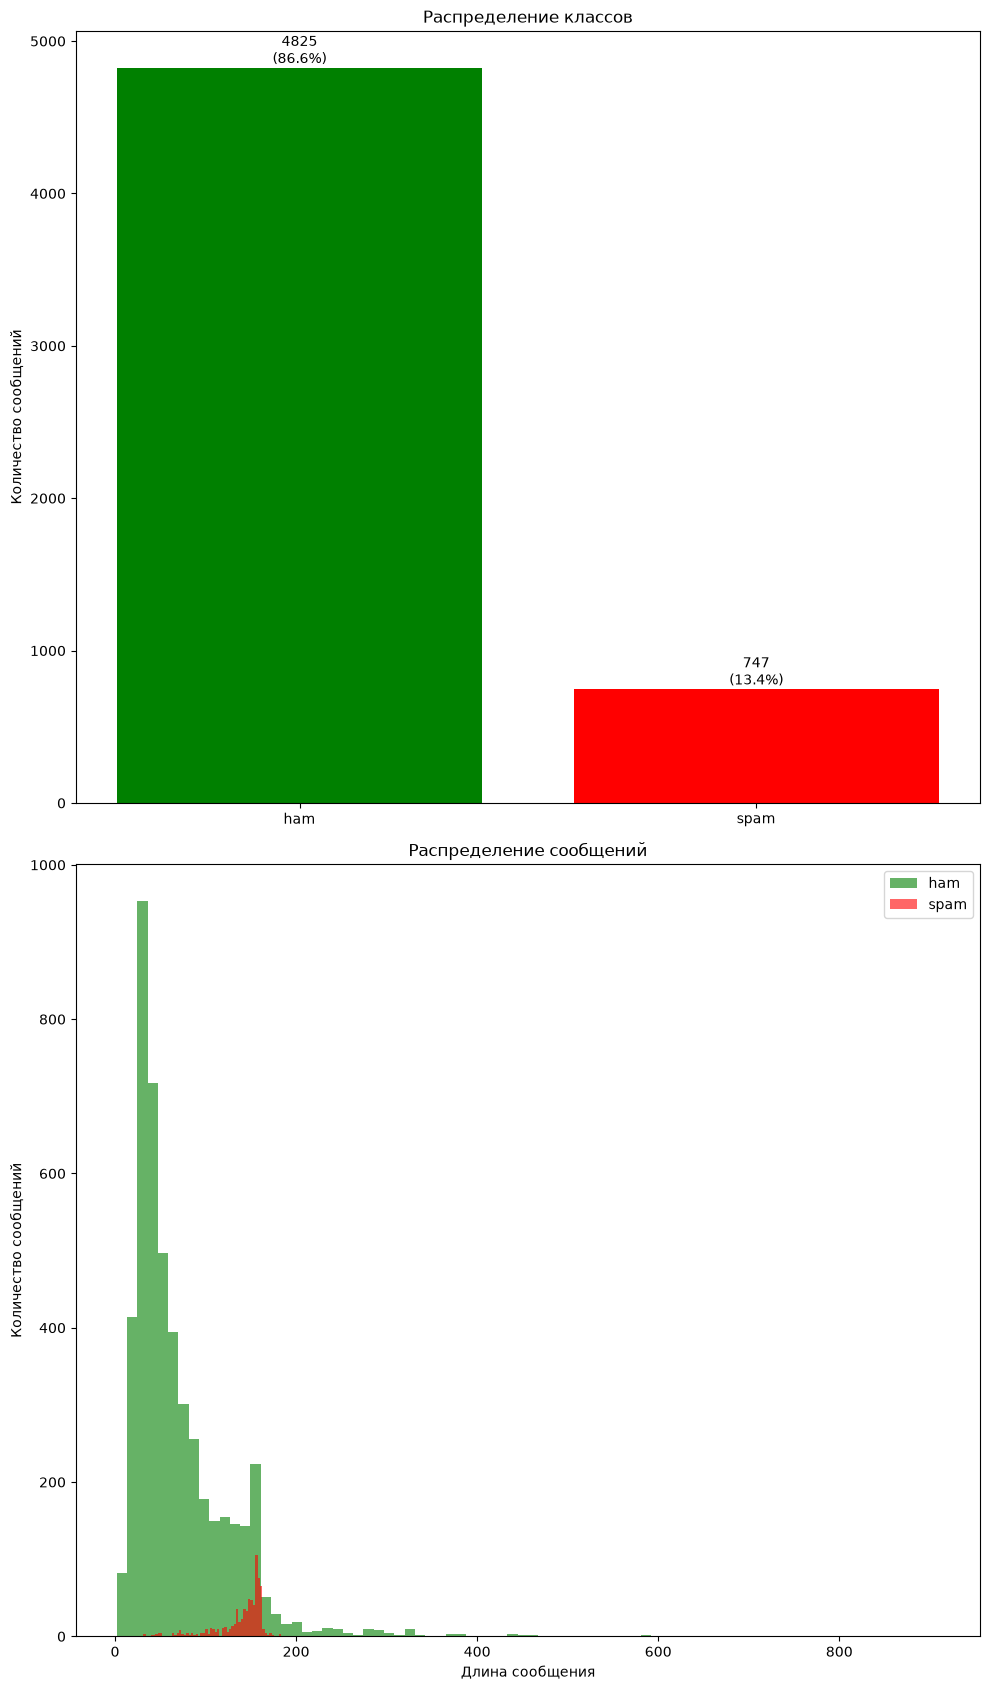

In [141]:
# Вывод графиков для первичного EDA

fig, axes = plt.subplots(2, 1, figsize=(10, 17))

# Столбчатая диаграмма
axes[0].bar(counts.index, counts.values, color=["g", "r"])

for ind, val in enumerate(counts.values):
    # 1: (0, 4825)
    # 2: (1, 747)
    
    # Подписи над столбцами
    axes[0].text(ind, val, f"{val}\n({val / len(df):.1%})", ha="center", va="bottom")

# Подписи первого графика
axes[0].set_title("Распределение классов")
axes[0].set_ylabel("Количество сообщений")

# Добавление дополнительного столбца в таблицу: длина сообщения
df["length"] = df["Text"].str.len()


for label, color in [("ham", "g"), ("spam", "r")]:

    # Гистрограмма для каждого из классов
    axes[1].hist(df.loc[df["Class"] == label, "length"], bins=80,
                 alpha=0.6, label=label, color=color)

# Подписи и легенда для второго графика    
axes[1].set_title("Распределение сообщений")
axes[1].set_ylabel("Количество сообщений")
axes[1].set_xlabel("Длина сообщения")
axes[1].legend()

# Автоматичекая подгонка отступов, чтобы подписи не наезжали
plt.tight_layout()   
plt.show()

**Вывод по EDA:**    
Спам-сообщения в среднем длиннее легитимных в 1.9 раз(видно по гистограмме и нижеприведённому коду) — длина сама по себе является информативным признаком, хотя в рамках наивного Байеса здесь используются только словесные признаки.

In [142]:
ham = df[df["Class"] == "ham"]["length"]
print(f"Средняя длина сообщений для класса \"ham\": {ham.mean()}")

Средняя длина сообщений для класса "ham": 71.48248704663213


In [143]:
spam = df[df["Class"] == "spam"]["length"]
print(f"Средняя длина сообщений для класса \"spam\": {spam.mean()}")

Средняя длина сообщений для класса "spam": 138.6706827309237


**Предварительная обработка текстов**  
Реализуем пайплайн предобработки:
1) Приведение к нижнему регистру,
2) Замена спам-характерных элементов (URL, номера телефонов, денежные суммы) на маркеры `<url>`, `<phone>`, `<money>`,
3) Токенизация
4) Удаление стоп-слов,
5) Стемминг

In [144]:
# Функция preprocess будет использоваться в качестве analyzer в векторизаторе CountVectorizer

# Скачивание около 200 английских стоп-слов
nltk.download("stopwords", quiet=True)
STOP_WORDS = set(nltk.corpus.stopwords.words("english"))

# Стемминг
stemming = nltk.stem.PorterStemmer().stem

def preprocess(text: str) -> list:
    
    text = text.lower()

    # Замена спам-сигналов на маркеры с помощью регулярных выражений
    text = re.sub(r"https?://\S+|www\.\S+", " <url> ", text) # Замена ссылки
    text = re.sub(r"(?<!\w)(?:\+?\d[\d\s().-]{6,}\d)(?!\w)", " <phone> ", text) # Замена номера телефона
    text = re.sub(r"(?:[$£€]\s?\d+(?:[.,]\d+)?|\d+(?:[.,]\d+)?\s?[$£€])", " <money> ", text) # Замена денежной суммы

    # Очистка лишних символов
    text = re.sub(r"[^a-z<>\d]+", " ", text)

    tokens = []
    for token in text.split():

        # Стоп слова пропускаются
        if token in STOP_WORDS:
            continue
        
        # Маркеры не стеммируются
        if token.startswith("<") and token.endswith(">"):
            tokens.append(token)    

        # Любое другие элементы стеммируются
        elif re.search(r"[a-z]", token) or token.isdigit():
            tokens.append(stemming(token))
        
    return tokens

**Разделение на обучающую и тестовую выборки**  
Стратифицированное разделение 80/20 с фиксированным `random_state` для воспроизводимости: состав тестовой выборки по классам пропорционален исходному.

In [145]:
# 1 = spam, 0 = ham
y = (df["Class"] == "spam").astype(int)   

# Разбиение с сохранением пропорции целевого класса (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    df["Text"], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Проверка на корректность разбиения
print(f"Обучающая выборка: {len(X_train)} сообщений "
      f"([{int(y_train.sum())} spam, {round(y_train.sum() / len(X_train) * 100,1)}%]", 
      f"[{len(y_train) - int(y_train.sum())} ham, " 
      f"{round((len(y_train) - int(y_train.sum())) / len(X_train) * 100,1)}%])")

print(f"Тестовая выборка: {len(X_test)} сообщений "
      f"([{int(y_test.sum())} spam, {round(y_test.sum() / len(X_test) * 100,1)}%]", 
      f"[{len(y_test) - int(y_test.sum())} ham, " 
      f"{round((len(y_test) - int(y_test.sum())) / len(X_test) * 100,1)}%])")

Обучающая выборка: 4457 сообщений ([598 spam, 13.4%] [3859 ham, 86.6%])
Тестовая выборка: 1115 сообщений ([149 spam, 13.4%] [966 ham, 86.6%])
